# Text classification and error analysis

After this block you can train and evaluate a text classifier on high-dimensional TF-IDF features for a task with almost 1,000 classes, read its errors, recognise leakage through a text that exists only after the decision, compress the sparse matrix with truncated SVD, and explain what word counts cannot capture. You also design the validation split your team reports on, compare it with a split by date, and prepare checkpoint 1 of the final project: your validation design and score on the class board.

## Overview

| Section | What it covers |
|---|---|
| The EBTI task: predicting the customs heading in 23 languages | the decision to support, the HS codes, the data and what the lecturer holds back, the long tail of headings, allowed inputs |
| Designing the validation split | what a split must answer, five designs, stratifying by heading with rare headings, two remedies for rare classes, a split stratified by heading and language, a split by date against the random split, which design to report |
| Linear models for text classification | scores as weighted sums of n-grams, naive Bayes, logistic regression and linear SVMs, a linear SVM and complement naive Bayes in a pipeline, a benchmark of eight classifiers |
| Metrics for almost 1,000 classes: accuracy, macro-F1, rare headings | per-class precision, recall and F1, macro, weighted and micro averages, accuracy or macro-F1, rare headings, top-k accuracy |
| Error analysis and the most informative n-grams | confusions between neighbouring headings, reading 20 errors, the most informative n-grams per class, average feature effects |
| Leakage through the customs' justification | target leakage, a model trained with the justification, the same leak in 20 Newsgroups |
| Dimensionality reduction with truncated SVD | latent semantic analysis, what the components capture, LSA features for a classifier, clustering descriptions with LSA and k-means |
| The limits of word counts | four blind spots, synonyms across languages, an unknown compound, from word counts to language models |
| Worked example | checkpoint 1 in four steps: the score with bootstrap intervals, the post for the class board, the API check of Session 16, refitting for the service |
| Check your understanding | five multiple-choice questions to vote on, discuss and vote again |
| Exercises | eleven exercises in pairs, among them a Parsons problem and a find-the-bug task |
| Debrief | what to compare afterwards, and the team project |
| Further reading | textbooks, papers, the scikit-learn examples and the extras of this block |

The modelling loop of this block, from the labelled decisions to checkpoint 1:

```mermaid
flowchart LR
    D["decisions.parquet<br/>(102,440)"] --> P["Split design<br/>(random, stratified<br/>by heading)"]
    P --> T["Training part<br/>(50,000 sample)"]
    T --> V["TfidfVectorizer"]
    V --> C["Linear SVM<br/>(SGDClassifier, hinge)"]
    C --> E["Validation part:<br/>accuracy, macro-F1,<br/>per-heading report"]
    P --> E
    E --> A["Error analysis:<br/>confusions, 20 errors,<br/>top n-grams"]
    A -->|"change features<br/>or data"| V
    E -->|"settings fixed"| S["Checkpoint 1:<br/>design + score<br/>on the class board"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## The EBTI task: predicting the customs heading in 23 languages

### The decision to support

Every product that crosses the EU border is classified in the customs tariff, and the classification decides the duty. A trader who is unsure can ask a customs authority for a **Binding Tariff Information** (BTI) decision: the trader describes the product, customs states its code, and the European Commission publishes all decisions in the EBTI database. Classifying takes an expert's time. A model that reads the description and proposes the most likely codes can save that time, provided we know how often it is right and where it fails.

### The codes: the Harmonized System

The tariff follows the Harmonized System (HS): 21 sections, 97 chapters (two digits, for example 64 footwear), about 1,200 **headings** (four digits, for example 6404 footwear with textile uppers) and finer subheadings. Our label is the four-digit heading. Think of a library: the section is the floor, the chapter the shelf, the heading the exact place on the shelf.

### The data

The data (see [case-study/README.md](../../../case-study/README.md)) are the decisions that were valid on 15 October 2026. A BTI decision is binding for three years, so all of them started between October 2023 and October 2026.

| Table in `case-study/data/ebti/` | Rows | What it contains |
|---|---|---|
| `decisions` | 102,440 decisions | description, language, issuing country, start date, the label `heading`, and columns customs wrote together with the decision (keywords, justification, full code) |
| `nomenclature/Nomenclature EN.xlsx` | 25,866 lines | the EU customs tariff (TARIC) as published, with the English text of every code; we look up the name of each heading |

The file comes **without a split**: choosing one is the next section. Before the file was made, the lecturer held back 17,074 further decisions of the same kind, drawn as one fold of seven, stratified by heading and language. They form the **final evaluation set** and are never released: after the code freeze the lecturer sends it to every team's API and compares the independent score with the score the team reported ([final project](../../17-18-final-presentations/final-project.md)).

Next we load the decisions and the English heading texts. `pd.read_excel(path, dtype=str)` reads the nomenclature with every cell as text; `.set_index("Goods code")["Description"]` makes it a lookup from code to text, and the line of a heading such as 6404 has the goods code `6404000000 80`. `DataFrame.columns.tolist()` lists the columns; `.dt.year` extracts the year of a date, and `value_counts()` counts the decisions per year.

In [2]:
import numpy as np
import pandas as pd

decisions = pd.read_parquet("case-study/data/ebti/decisions.parquet")
taric = pd.read_excel("case-study/data/ebti/nomenclature/Nomenclature EN.xlsx", dtype=str).set_index("Goods code")["Description"]
heading_text = pd.Series({h: taric[f"{h}000000 80"] for h in sorted(decisions["heading"].unique())})
print(len(decisions), "decisions,", decisions["heading"].nunique(), "headings,",
      decisions["language"].nunique(), "languages")
print("columns:", decisions.columns.tolist())
print("decisions per start year:", decisions["start_date"].dt.year.value_counts().sort_index().to_dict())

102440 decisions, 1009 headings, 23 languages
columns: ['bti_reference', 'issuing_country', 'language', 'start_date', 'end_date', 'date_of_issue', 'description', 'keywords', 'classification_justification', 'cn_code', 'heading', 'chapter']
decisions per start year: {2023: 6638, 2024: 33252, 2025: 34849, 2026: 27701}


### The long tail of headings

**Predict.** The most frequent heading is 3926 ("other articles of plastics"). What share of all decisions do you expect it to have: 4 %, 14 % or 40 %? And how many headings have fewer than ten decisions?

In [3]:
counts = decisions["heading"].value_counts()
top = counts.head(5).to_frame("n").assign(share=lambda d: (d["n"] / len(decisions)).round(3))
top["name"] = heading_text.reindex(top.index).str[:45]
print(top)
print((counts < 10).sum(), "of", len(counts), "headings have fewer than 10 decisions")

            n  share                                           name
heading                                                            
3926     4311  0.042  Other articles of plastics and articles of ot
9503     3335  0.033  Tricycles, scooters, pedal cars and similar w
6307     3047  0.030  Other made-up articles, including dress patte
4202     2901  0.028  Trunks, suitcases, vanity cases, executive-ca
2106     2742  0.027  Food preparations not elsewhere specified or 
377 of 1009 headings have fewer than 10 decisions


The headings have a **long tail**: a few hundred frequent headings and many rare ones. This shapes everything that follows, from the choice of model to the choice of metric.

### Allowed inputs

> **Note.** `keywords`, `classification_justification`, `cn_code`, `chapter`, `date_of_issue` and `end_date` are written by customs together with or after the decision. A request to your API contains only the description and, optionally, the language (final project), so these columns must not be model inputs. The section on leakage below measures what happens when this rule is broken. They may be used for *reading* decisions during error analysis.

**In practice.** The final project is evaluated like a deployment: decisions that no team has seen are sent to the team's service, and the independent score is compared with the score the team reported. Kaggle competitions use a hidden test set for the same reason. Decisions can be looked up in the public EBTI database, so the independent score is not converted into marks; what counts is how well a team's reported score predicts it.

## Designing the validation split

`decisions.parquet` comes without a split. How you divide it into decisions to learn from and decisions to judge the model on is the first design decision of the final project, and a reported score is only as good as this design. The validation decisions must look like the decisions the model will meet later, and they must play no part in fitting the model.

### What a split must answer

Every split answers one question. Sessions 7 and 9 introduced these designs on the Airbnb data:

| Design | How | Question it answers | On the EBTI decisions |
|---|---|---|---|
| random | draw validation decisions at random | how well does the model classify decisions like those in the file? | simple; with many rare headings the shares of a heading can differ between the parts |
| random, stratified by heading | the same share of every heading in both parts | the same question, with the same mix of headings in both parts | headings with a single decision need a remedy (below) |
| random, stratified by heading and language | the same share of every heading-language combination in both parts | the same question, with the same mix of headings and of languages | the lecturer drew the independent evaluation set this way: one fold of seven |
| by date | train on the older decisions, validate on the newest | how well will the model classify next year's requests? | deployment always meets the future |
| grouped | near-identical texts (for example one trader's series of products) on the same side | does the model generalise to new products, not only to variants of known ones? | needs a definition of "near-identical" (Session 9) |

Things to weigh on this file: about 1,000 headings, many of them with fewer than ten decisions; 23 languages; decisions from late 2023 to 2026; near-identical texts, although exact repeats were removed. In this block we build the random split stratified by heading and language and compare it with a split by date.

### Stratifying by heading, and the rare headings

`train_test_split(data, test_size=n, stratify=labels)` draws a random split in which every label has the same share in both parts. **Predict.** Will stratifying by heading work on this file? `try`/`except ValueError` catches the error, so that the notebook continues.

In [4]:
from sklearn.model_selection import train_test_split

try:
    train_test_split(decisions, test_size=1/7, stratify=decisions["heading"], random_state=0)
except ValueError as err:
    print("ValueError:", str(err)[:115], "...")

ValueError: The least populated classes in y have only 1 member, which is too few. The minimum number of groups for any class c ...


A heading with a single decision cannot be in both parts, and `train_test_split` refuses to split at all. Session 7 showed two remedies:

- **Pool the rare classes.** Put all headings with fewer than, say, ten decisions into one stratum `"rare"` and stratify on that.
- **Keep one fold of a stratified k-fold split.** `StratifiedKFold` accepts classes with fewer members than folds: it only warns, and each such class ends up on one side. A heading with one decision is then either a training heading or a validation heading the model cannot know.

We use the second, simpler remedy, and stratify by **heading and language together**, as the lecturer did for the independent evaluation set. Two criteria become one stratification label per decision, the string `heading + "|" + language` (for example `6404|de`), so each combination gets about the same share in both parts and the language mix, which matters a lot for the scores (Session 16), is the same. `StratifiedKFold(n_splits=7, shuffle=True, random_state=0)` divides the decisions into seven folds; `next(folds.split(X, labels))` returns the row positions of the first split: six folds for training, one (about 14 %) for validation. The fixed `random_state` gives everyone in class the same split. This is **one possible design**: your team chooses its own and justifies it.

**Predict.** How many heading-language combinations have a single decision, and what will scikit-learn say about them?

In [5]:
from sklearn.model_selection import StratifiedKFold

key = decisions["heading"] + "|" + decisions["language"]
print(key.nunique(), "heading-language combinations,", (key.value_counts() == 1).sum(), "of them with one decision")
folds = StratifiedKFold(n_splits=7, shuffle=True, random_state=0)
train_rows, valid_rows = next(folds.split(decisions, key))
train_full, valid = decisions.iloc[train_rows], decisions.iloc[valid_rows]
print(len(train_full), "training decisions,", len(valid), "validation decisions")
print(pd.DataFrame({name: d["language"].value_counts(normalize=True).head(5).round(3)
                    for name, d in [("training", train_full), ("validation", valid)]}))
print((~valid["heading"].isin(train_full["heading"])).sum(), "validation decisions with a heading unseen in training")

5361 heading-language combinations, 1786 of them with one decision


87805 training decisions, 14635 validation decisions
          training  validation
language                      
cs           0.037       0.035
de           0.610       0.610
es           0.037       0.036
fr           0.156       0.156
nl           0.040       0.040


/Users/danielle/Documents/code/python_ml_ai/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=7.
  warnings.warn(


22 validation decisions with a heading unseen in training


The warning is the one discussed above: combinations with a single decision cannot be spread over seven folds, so each lands in one of them. Both parts have the same mix of languages, and almost every validation heading occurs in training; the few that do not are headings the model cannot get right. To keep the cells of this block fast, the experiments train on a random **sample of 50,000** training decisions, drawn with `DataFrame.sample(n, random_state=0)`. The validation part stays the same for every model, so all scores of the block can be compared.

In [6]:
train = train_full.sample(50_000, random_state=0)
print(len(train), "sample decisions,", train["heading"].nunique(), "headings,",
      (~valid["heading"].isin(train["heading"])).sum(), "validation decisions with a heading unseen in the sample")

50000 sample decisions, 931 headings, 38 validation decisions with a heading unseen in the sample


### A split by date against the random split

The random split answers "how well does the model classify decisions like the ones in the database?". A deployed model faces another question: it is trained on all decisions up to today and classifies **next** year's requests. A **split by date** imitates this: train on the older decisions, validate on the newest.

Why could the two differ? Products and wording change over time (new kinds of goods, new phrasing in the customs offices), a trader often asks for several similar decisions within a few weeks, so near-repeats cluster in time, and a heading that is rare in the older decisions may become frequent later. In a random split every validation decision has training decisions from the same weeks; in a split by date it has none.

To compare like with like, both designs validate on the same number of decisions and train on 50,000 decisions drawn from their training part. The model is the TF-IDF classifier with a linear SVM that the next section explains; here it is only the measuring instrument. `sort_values("start_date")` orders the decisions by date, and `.iloc[-n:]` takes the last n rows.

**Predict.** Will the split by date report a higher or a lower accuracy than the random split?

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline

by_date = decisions.sort_values("start_date")
date_train, date_valid = by_date.iloc[:-len(valid)], by_date.iloc[-len(valid):]
print("by date: train", date_train["start_date"].min().date(), "to", date_train["start_date"].max().date(),
      "| validate", date_valid["start_date"].min().date(), "to", date_valid["start_date"].max().date())
split_scores = {}
for name, tr, va in [("random, stratified", train, valid),
                     ("by date", date_train.sample(50_000, random_state=0), date_valid)]:
    m = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True),
                      SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0, n_jobs=-1))
    p = m.fit(tr["description"], tr["heading"]).predict(va["description"])
    split_scores[name] = accuracy_score(va["heading"], p), f1_score(va["heading"], p, average="macro")
    print(f"{name:19s} accuracy {split_scores[name][0]:.3f}  macro-F1 {split_scores[name][1]:.3f}  | "
          f"exact repeats of a training text {va['description'].isin(tr['description']).mean():.3f}, "
          f"heading unseen in training {(~va['heading'].isin(tr['heading'])).mean():.3f}")

by date: train 2023-10-16 to 2026-05-18 | validate 2026-05-18 to 2026-10-13


random, stratified  accuracy 0.856  macro-F1 0.667  | exact repeats of a training text 0.000, heading unseen in training 0.003


by date             accuracy 0.765  macro-F1 0.520  | exact repeats of a training text 0.000, heading unseen in training 0.003


The split by date reports 0.765 accuracy against 0.856 for the random split, with the same number of training decisions, and macro-F1 falls from 0.667 to 0.520. Exact repeats explain none of the gap (the course data contain none), and headings unseen in training explain very little (0.3 % of the validation decisions in both designs). The rest is change over time: in the random split every validation decision has training decisions from the same weeks (the same products, the same traders asking about similar goods, the same templates of a customs office), while the newest decisions, from May to October 2026, have to be classified from what was decided before.

### Which design to report

Which number predicts the independent score of the final project? The lecturer's evaluation set was drawn from the same decisions as one fold of seven, stratified by heading and language, so the **random stratified** validation score is the one to compare with it. The split by date is a second, harder number to report next to it: what to expect from next year's requests (Session 16 looks at drift between start years). Two more rules make a reported score trustworthy:

- **The validation decisions play no part in fitting or choosing.** Every setting chosen by looking at the validation score makes that score a little optimistic. When a team compares many models, it keeps a last part aside (or tunes by cross-validation on the training part, Session 7) and measures the final design on it once.
- **The score comes with its uncertainty.** The worked example computes a bootstrap interval.

**In practice.** Credit-scoring and forecasting teams validate "out of time" for the same reason. Kapoor and Narayanan (2023) list random splits of temporal data among the common forms of leakage in published machine-learning studies.

## Linear models for text classification

### Scores as weighted sums of n-grams

A **linear classifier** computes one score per class as a weighted sum of the features plus an intercept, score_k(d) = b_k + Σ_j w_kj · x_dj, and predicts the class with the highest score. For text each feature is an n-gram, so each weight says how much that n-gram pushes a description towards a heading. It works like a points system: every word in the description adds or subtracts points for every heading, and the heading with most points wins.

By hand: the weights for heading 6404 (textile uppers) and the TF-IDF values of one description are

| n-gram | weight (6404) | value | product |
|---|---|---|---|
| textile | 2.0 | 0.5 | 1.0 |
| leather | −3.0 | 0.4 | −1.2 |
| textile upper | 4.0 | 0.6 | 2.4 |

With intercept −1.0 the score for 6404 is −1.0 + 1.0 − 1.2 + 2.4 = 1.2. The model computes such a score for every heading and picks the largest.

### Naive Bayes, logistic regression and linear SVMs

Three linear classifiers are common for text:

| Model | Idea | Output | Notes |
|---|---|---|---|
| multinomial or complement naive Bayes | word probabilities per class, assumed independent | probabilities (poorly calibrated) | very fast; works on counts |
| logistic regression | minimises log-loss; softmax turns scores into probabilities (Session 6) | probabilities | slow with 1,000 classes and 100,000 features |
| linear support vector machine | maximises the margin between classes | scores only | here trained with `SGDClassifier(loss="hinge")` |

With many classes scikit-learn trains one binary model per class ("one versus rest"). `SGDClassifier` fits them by **stochastic gradient descent**: it passes over the data `max_iter` times and updates the weights after each example, which is fast enough for tens of thousands of decisions and almost 1,000 headings. `alpha` is the strength of the regularisation penalty (larger means simpler models); `LogisticRegression` and `LinearSVC` use `C`, its inverse.

Linear models suit text because the data are sparse and high-dimensional: with tens of thousands of columns, most classes can be separated by a hyperplane, and the fitted weights belong to readable n-grams.

### A linear SVM and naive Bayes in a pipeline

Next we put the vectoriser and the classifier into one pipeline with `make_pipeline`, so that `fit` learns vocabulary and idf from the training decisions only. `time.perf_counter()` measures the fitting time; `accuracy_score` and `f1_score(..., average="macro")` are explained in the next section.

In [8]:
import time

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline


def svm():
    # A linear SVM fitted by stochastic gradient descent: fast with 1,000 classes.
    return SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0, n_jobs=-1)


def report(name, y_true, y_pred, t0=None):
    secs = f"  {time.perf_counter() - t0:4.0f} s" if t0 else ""
    print(f"{name:32s} accuracy {accuracy_score(y_true, y_pred):.3f}  "
          f"macro-F1 {f1_score(y_true, y_pred, average='macro'):.3f}{secs}")

Next we fit the word model, TF-IDF and the linear SVM in one pipeline, on the 50,000 sample decisions, and report it on the validation part.

In [9]:
t0 = time.perf_counter()
model = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), svm())
model.fit(train["description"], train["heading"])
pred = model.predict(valid["description"])
report("linear SVM, word TF-IDF", valid["heading"], pred, t0)

linear SVM, word TF-IDF          accuracy 0.856  macro-F1 0.667    36 s


**Predict.** Complement naive Bayes on word counts is one of the fastest text classifiers. Will it be better or worse than the linear SVM here? `ComplementNB` is a variant of naive Bayes designed for unbalanced classes.

In [10]:
from sklearn.naive_bayes import ComplementNB

t0 = time.perf_counter()
nb = make_pipeline(CountVectorizer(min_df=2), ComplementNB()).fit(train["description"], train["heading"])
report("complement naive Bayes, counts", valid["heading"], nb.predict(valid["description"]), t0)

complement naive Bayes, counts   accuracy 0.734  macro-F1 0.479    14 s


The case-study README gives reference values for a split of the same design: word TF-IDF with a linear SVM reaches 0.856 accuracy when trained on 50,000 decisions and 0.877 on the full training part of 87,805, and character n-grams (3–5) on the full training part reach 0.885 (case-study README, 2026). More data helps more than a cleverer representation. Our split gives the same 0.856 with the same settings and the same amount of training data. Do not expect such agreement in general: another random split or another sample moves the score, and a team that reports a score therefore repeats its split a few times (Session 7).

> **Note.** Choose the analyzer, n-gram range, `min_df` and `alpha` on the validation part, and remember that each choice made by looking at it makes its score a little optimistic (see the split section).

**In practice.** Routing e-mails and support tickets to the right team is often done with TF-IDF and a linear model, because it is cheap to retrain when categories change. Joulin et al. (2017) showed with fastText that a linear classifier on word and character n-grams comes close to deep neural networks on standard text-classification benchmarks while training in seconds.

### Benchmarking classifiers on sparse text features

*Adapted from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

scikit-learn offers many classifiers. Here we train eight of them on the same text task and measure both accuracy and speed, at training and at prediction time. To keep it fast we use a smaller task: the headings of four chapters, 39 (plastics), 64 (footwear), 85 (electrical machinery) and 95 (toys and games). The vectoriser drops words in more than half of the documents (`max_df=0.5`) and words in fewer than five (`min_df=5`).

In [11]:
chapters = ["39", "64", "85", "95"]
small_tr = train[train["chapter"].isin(chapters)]
small_va = valid[valid["chapter"].isin(chapters)]
vec_small = TfidfVectorizer(sublinear_tf=True, max_df=0.5, min_df=5)
X_train = vec_small.fit_transform(small_tr["description"])
X_test = vec_small.transform(small_va["description"])
y_train, y_test = small_tr["heading"], small_va["heading"]
print(f"{X_train.shape[0]:,} training and {X_test.shape[0]:,} validation decisions, "
      f"{X_train.shape[1]:,} features, {y_train.nunique()} headings")

14,251 training and 4,190 validation decisions, 15,874 features, 86 headings


The benchmark function fits one classifier, times training and prediction, and returns accuracy and both times. `sklearn.utils.extmath.density` gives the share of non-zero coefficients.

In [12]:
from sklearn.utils.extmath import density


def benchmark(clf, name):
    t0 = time.perf_counter()
    clf.fit(X_train, y_train)
    train_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    score = accuracy_score(y_test, clf.predict(X_test))
    test_time = time.perf_counter() - t0
    dens = f", coefficient density {density(clf.coef_):.2f}" if hasattr(clf, "coef_") else ""
    print(f"{name:24s} accuracy {score:.3f}, train {train_time:6.2f} s, test {test_time:5.2f} s{dens}")
    return name, score, train_time, test_time

Next we run eight classifiers. Their hyperparameters were tuned on the 20 Newsgroups data in the original example, not on ours, so treat the ranking as rough. (The original stops the log-loss SGD early on an internal validation split; that split fails here because some headings have a single training decision, so we leave early stopping off.) `NearestCentroid` (the Rocchio classifier) assigns a document to the class whose average TF-IDF vector is closest.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.svm import LinearSVC

results = [benchmark(clf, name) for clf, name in [
    (LogisticRegression(C=5, max_iter=1000), "logistic regression"),
    (RidgeClassifier(alpha=1.0, solver="sparse_cg"), "ridge classifier"),
    (KNeighborsClassifier(n_neighbors=100), "kNN"),
    (RandomForestClassifier(n_jobs=-1, random_state=0), "random forest"),
    (LinearSVC(C=0.1), "linear SVC"),
    (SGDClassifier(loss="log_loss", alpha=1e-4, n_iter_no_change=3, random_state=0), "log-loss SGD"),
    (NearestCentroid(), "nearest centroid"),
    (ComplementNB(alpha=0.1), "complement naive Bayes"),
]]

logistic regression      accuracy 0.882, train  35.40 s, test  0.04 s, coefficient density 1.00


ridge classifier         accuracy 0.900, train  14.09 s, test  0.06 s, coefficient density 1.00


kNN                      accuracy 0.757, train   0.03 s, test  2.14 s


random forest            accuracy 0.855, train   1.38 s, test  0.04 s


linear SVC               accuracy 0.873, train   6.63 s, test  0.02 s, coefficient density 0.90


log-loss SGD             accuracy 0.814, train   0.97 s, test  0.01 s, coefficient density 1.00


nearest centroid         accuracy 0.697, train   1.15 s, test  0.07 s
complement naive Bayes   accuracy 0.833, train   0.05 s, test  0.01 s


Next we plot the trade-off between accuracy and training time, and between accuracy and prediction time, on a logarithmic time axis (`yscale="log"`); `ax.annotate` writes the name next to each point.

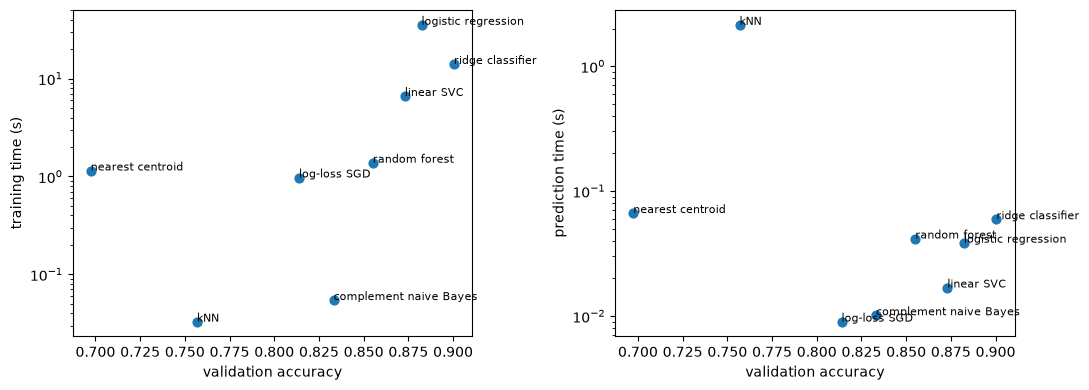

In [14]:
import matplotlib.pyplot as plt

names, score, train_time, test_time = map(np.array, zip(*results))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t, label in [(axes[0], train_time, "training time (s)"), (axes[1], test_time, "prediction time (s)")]:
    ax.scatter(score.astype(float), t.astype(float), s=40)
    ax.set(yscale="log", xlabel="validation accuracy", ylabel=label)
    for n, x, y in zip(names, score.astype(float), t.astype(float)):
        ax.annotate(n, (x, y), fontsize=8)
plt.tight_layout()
plt.show()

**What do you see?** Which models sit furthest to the right in both panels, and which model sits highest in the right panel?

How to read the plots (the exact times depend on your laptop). The original example concludes that for high-dimensional text, linear models are usually the best fit: with thousands of dimensions most classes become linearly separable. Our run agrees: the ridge classifier, logistic regression and the linear SVC reach the highest accuracies. Once trained, all linear models predict at about the same speed, because they share the same prediction function (one weighted sum per class); their training times differ because of the loss and the solver. Complement naive Bayes trains fastest of the models that learn weights (k-nearest neighbours only stores the training documents) and is still competitive. The random forest trains quickly here because it uses all processor cores, but it is less accurate than the best linear models: trees split on one feature at a time, which suits thousands of sparse columns poorly. k-nearest neighbours has the longest prediction time and, with nearest centroid, the lowest accuracy: each prediction compares the document with every training document, and in this high-dimensional space distances say little (the "curse of dimensionality").

> 📖 **Read more:** [extras/04-sklearn-text-classification-sparse-features.ipynb](extras/04-sklearn-text-classification-sparse-features.ipynb) (scikit-learn gallery): the original benchmark on 20 Newsgroups posts, with confusion matrices and feature effects before and after stripping e-mail metadata.

## Metrics for almost 1,000 classes: accuracy, macro-F1, rare headings

### Precision, recall and F1 per class

With two classes Session 8 computed precision, recall and F1 for the positive class. With many classes the same measures are computed **per class**, treating that class as positive and all others as negative:

- **precision** of heading k = correct predictions of k / all predictions of k ("when the model says 9503, how often is it right?");
- **recall** of heading k = correct predictions of k / all true members of k ("of all toy decisions, how many does it find?");
- **F1** = 2 × precision × recall / (precision + recall), low if either is low;
- **support** = the number of true members of k.

### Macro, weighted and micro averages

Three averages summarise the per-class values:

| Average | Definition | Effect with rare classes |
|---|---|---|
| macro | plain mean of the per-class F1 values | every heading counts equally, also one with a single decision |
| weighted | mean weighted by support | dominated by frequent headings |
| micro | computed from all predictions pooled; equals accuracy for single-label tasks | dominated by frequent headings |

By hand with ten decisions: six of 3926, two of 6403, two of 6404. The model gets all six 3926 right, one of each footwear heading, and predicts 3926 for the other two. Precision of 3926 is 6/8, recall 6/6, F1 0.86; F1 is 0.67 for each footwear heading. Macro-F1 = (0.86 + 0.67 + 0.67) / 3 = 0.73, accuracy = 8/10 = 0.80.

Next we check the hand computation. `average=None` returns one F1 per class; `labels=` fixes their order.

In [15]:
y_true = ["3926"] * 6 + ["6403", "6403", "6404", "6404"]
y_pred = ["3926"] * 6 + ["3926", "6403", "3926", "6404"]
print(f1_score(y_true, y_pred, average=None, labels=["3926", "6403", "6404"]).round(2))
print(round(f1_score(y_true, y_pred, average="macro"), 2), accuracy_score(y_true, y_pred))

[0.86 0.67 0.67]
0.73 0.8


### Accuracy or macro-F1?

Accuracy answers "what share of requests gets the right suggestion?", which drives an officer's workload, so the final project reports it first. Macro-F1 answers "how well does the model know the tariff as a whole?" and keeps the long tail visible.

**Predict.** Always predicting 3926 on the validation set. What accuracy, and what macro-F1?

In [16]:
always_3926 = np.repeat("3926", len(valid))
report("always 3926", valid["heading"], always_3926)
for avg in ["macro", "weighted", "micro"]:
    print(f"word model, {avg:8s} F1 {f1_score(valid['heading'], pred, average=avg, zero_division=0):.3f}")

always 3926                      accuracy 0.042  macro-F1 0.000
word model, macro    F1 0.667
word model, weighted F1 0.850
word model, micro    F1 0.856


### Rare headings

A list of hundreds of per-heading F1 values cannot be read, but two views can: the per-heading report sorted by support, and the mean F1 of headings grouped by how many training decisions they have. `classification_report(..., output_dict=True)` returns the per-class values as a dictionary; the last three rows are the averages, which we drop.

In [17]:
from sklearn.metrics import classification_report

per_heading = pd.DataFrame(classification_report(valid["heading"], pred, output_dict=True,
                                                 zero_division=0)).T.iloc[:-3]
print(per_heading.sort_values("support", ascending=False).head(5).round(2))
print(len(per_heading), "headings in the validation set;", int((per_heading["f1-score"] == 0).sum()),
      "with F1 = 0;", int((per_heading["support"] < 5).sum()), "with fewer than 5 decisions")

      precision  recall  f1-score  support
3926       0.80    0.89      0.84    614.0
9503       0.92    0.96      0.94    476.0
6307       0.86    0.94      0.90    434.0
4202       0.94    0.97      0.96    417.0
2106       0.83    0.94      0.88    391.0
815 headings in the validation set; 148 with F1 = 0; 429 with fewer than 5 decisions


Next we group the headings by their number of training decisions with `pd.cut` and average F1 per group.

In [18]:
n_train = train["heading"].value_counts().reindex(per_heading.index, fill_value=0)
bins = pd.cut(n_train, [-1, 0, 10, 50, 200, np.inf], labels=["0", "1-10", "11-50", "51-200", ">200"])
per_heading["f1-score"].groupby(bins, observed=True).agg(["mean", "count"]).round(2)

,mean,count
count,,
0,0.00,33
1-10,0.53,333
11-50,0.79,261
51-200,0.85,132
>200,0.88,56


F1 rises steeply with the number of training examples, and headings never seen in training cannot be predicted at all. More data for rare headings helps more than tuning the frequent ones: on the validation set, going from the sample to the full training set raises macro-F1 from 0.667 to 0.706 and accuracy from 0.856 to 0.877 (case-study README, on a split of the same design).

> **Note.** `f1_score` with more than two classes needs `average=`; always say which average you report. Macro-F1 also depends on which classes appear in the evaluation data, so compare macro-F1 values only on the same data.

### Top-k accuracy

An officer can check three suggestions in seconds, so a model whose second or third suggestion is often right is more useful than its accuracy says. **Top-k accuracy** counts a prediction as correct if the true heading is among the k highest-scoring headings. `decision_function` returns one score per heading, `np.argsort(-scores, axis=1)` sorts each row from high to low, and `classes_` maps column numbers to headings.

In [19]:
scores = model.decision_function(valid["description"])
order = np.argsort(-scores, axis=1)
y_val = valid["heading"].to_numpy()
classes = model.classes_
for k in [1, 3, 5, 10]:
    print(f"top-{k:<2d} accuracy {(classes[order[:, :k]] == y_val[:, None]).any(axis=1).mean():.3f}")

top-1  accuracy 0.856
top-3  accuracy 0.910
top-5  accuracy 0.924
top-10 accuracy 0.935


## Error analysis and the most informative n-grams

A score says how often a model fails, not why. **Error analysis** means reading a sample of misclassified examples, sorting them into categories and counting. It turns a score into a list of next steps and prevents a common waste of time: tuning hyperparameters when the real problem lies in the data or the task.

```mermaid
flowchart LR
    A["Validation<br/>predictions"] --> B["Where are the errors?<br/>(confusion, top pairs)"]
    B --> C["Read a sample of errors<br/>with keywords and<br/>heading texts"]
    C --> D["Sort into<br/>categories"]
    D --> E["Count per<br/>category"]
    E --> F{"Fixable with<br/>text features?"}
    F -->|yes| G["Change features<br/>or data, re-validate"]
    F -->|no| H["Accept, document,<br/>or route to a person"]
    G --> A
```

### Confusion between neighbouring headings

A **confusion matrix** counts, for every true class (row), how often each class was predicted (column). With 1,000 headings it has a million cells, so we look at **groups of neighbouring headings** (one chapter) and at the **most frequent pairs** of true and predicted heading.

*The confusion-matrix plot is adapted from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause).* Next we draw it for the six footwear headings 6401–6406 with `ConfusionMatrixDisplay.from_predictions`; `labels=` restricts it to these headings.

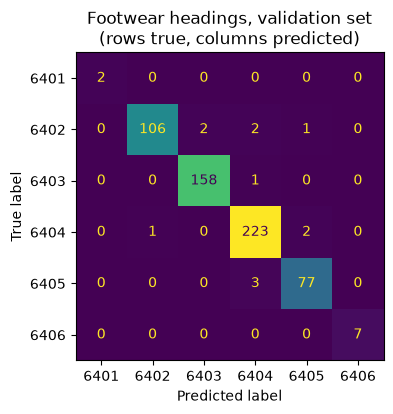

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

shoes = ["6401", "6402", "6403", "6404", "6405", "6406"]
in64 = valid["heading"].isin(shoes).to_numpy()
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(valid["heading"][in64], pred[in64], labels=shoes, ax=ax, colorbar=False)
ax.set_title("Footwear headings, validation set\n(rows true, columns predicted)")
plt.show()

**What do you see?** Find the row with the most decisions off the diagonal, and say where they went.

Read along a row: how are the true decisions of one heading spread over the predictions? Footwear is classified almost perfectly here, because the material words of the tariff (leather, textile, rubber, plastics) occur in nearly every description. The few errors sit between neighbours: 6402 (rubber or plastic uppers) loses 5 of its 111 validation decisions, 2 to 6403 (leather uppers), 2 to 6404 (textile uppers) and 1 to 6405; 6404 loses 3 decisions (2 to 6405, 1 to 6402) and 6405 loses 3 to 6404. The small headings 6401 (waterproof footwear) and 6406 (parts of footwear) have only 2 and 7 validation decisions, all classified correctly: far too few to judge them.

Next we count the most frequent true–predicted pairs over all headings and add the heading texts with `.map`.

**Predict.** The word model gets 2,111 validation decisions wrong. What share of these errors stays inside the right chapter (the same first two digits): about 10 %, 30 % or 70 %?

In [21]:
val = valid.assign(pred=pred)
wrong = val[val["heading"] != val["pred"]]
print(len(wrong), "errors; share inside the right chapter:",
      round((wrong["heading"].str[:2] == wrong["pred"].str[:2]).mean(), 2))
pairs = wrong[["heading", "pred"]].value_counts().head(6).rename("n").reset_index()
pairs["true_name"] = pairs["heading"].map(heading_text).str[:35]
pairs["pred_name"] = pairs["pred"].map(heading_text).str[:35]
pairs

2111 errors; share inside the right chapter: 0.31


,heading,pred,n,true_name,pred_name
0,3924,3926,14,"Tableware, kitchenware, other house",Other articles of plastics and arti
1,7326,7318,9,Other articles of iron or steel,"Screws, bolts, nuts, coach screws,"
2,8544,8536,8,Insulated (including enamelled or a,Electrical apparatus for switching
3,8302,7326,8,"Base-metal mountings, fittings and",Other articles of iron or steel
4,2202,2106,7,"Waters, including mineral waters an",Food preparations not elsewhere spe
5,8708,3926,6,Parts and accessories of the motor,Other articles of plastics and arti


### Reading 20 errors

For a multilingual corpus two reading aids make error analysis possible for everyone: the English **keywords** customs assigned to each training decision and the English **heading texts** from the nomenclature. Neither is a model input. Next we draw 20 errors with a fixed seed, so that the whole class reads the same decisions, and show them side by side.

In [22]:
pd.set_option("display.max_colwidth", 110)
errors20 = wrong.sample(20, random_state=1)
table = pd.DataFrame({
    "lang": errors20["language"],
    "true": errors20["heading"] + " " + errors20["heading"].map(heading_text).str[:40],
    "predicted": errors20["pred"] + " " + errors20["pred"].map(heading_text).str[:40],
    "keywords": errors20["keywords"].str[:70],
})
table

,lang,true,predicted,keywords
28751,de,"8713 Carriages for disabled persons, whether",8714 Parts and accessories of vehicles of hea,"BATTERY-OPERATED,BY BATTERY,COLLAPSIBLE,ELECTRIC,FOR DISABLED PERSONS,"
17758,nl,3823 Industrial monocarboxylic fatty acids; a,3824 Prepared binders for foundry moulds or c,"AS GRAINS,AS GRANULES,BOVINE ANIMALS,FATTY ACIDS,FEED,MILK,PALM OIL,PA"
12172,fr,"9003 Frames and mountings for spectacles, gog","9004 Spectacles, goggles and the like, correc","FOR CHILDREN,OF PLASTICS,POLYCARBONATES,SPECTACLE FRAMES,SPECTACLES"
96915,cs,3203 Colouring matter of vegetable or animal,1211 Plants and parts of plants (including se,"CAPSICUM,DYES,NATURAL,OF VEGETABLE ORIGIN,PAPRIKA EXTRACT,RED"
85900,sk,"3307 Pre-shave, shaving or aftershave prepara",3824 Prepared binders for foundry moulds or c,"BALSAMS,CAMPHOR,ESSENTIAL OILS,FOR OUTDOOR USE,NOSE,OILS,PREPARED,PUT"
98437,fr,6815 Articles of stone or of other mineral su,8708 Parts and accessories of the motor vehic,"CARBON,CARBOYS,CASINGS,HYDROGEN,POLYAMIDES,RESERVOIRS,RESINS"
64612,nl,7326 Other articles of iron or steel,7308 Structures (excluding prefabricated buil,"ANCHORS,FOR CONCRETE,FOR COUPLING,FOR LIFTING,OF BASE METALS,OF STAINL"
93550,fr,"8215 Spoons, forks, ladles, skimmers, cake-se",8205 Hand tools (including glaziers' diamonds,"CHEESE,FORKS,OF BASE METALS,OF STAINLESS STEEL,WITH HANDLE"
71524,fr,"6304 Other furnishing articles, excluding tho","6505 Hats and other headgear, knitted or croc","FIBRES,FISHING NETS,INSECTS,MADE UP,MOSQUITO NETS,OF POLYESTER"
72873,fr,3304 Beauty or make-up preparations and prepa,3305 Preparations for use on the hair,"AVOCADOS,HANDS,IN TUBES,PUT UP FOR RETAIL SALE,SKIN FOODS,SKINCARE PRE"


The course team sorted these 20 errors by hand into categories, reading the keywords and the heading texts. Your own categories may differ; the point is to count.

| Category | Example in the 20 errors | Count |
|---|---|---|
| borderline between related headings (the legal notes decide) | steel lifting anchors for concrete parts (7326, predicted 7308 structures), an LED strip 8539/9405, balancing spectacle frames without lenses 9003/9004, pressed paper decorations 4823/4911, a mosquito net for a carrycot 6304/6505 | 5 |
| material versus function (the model and the tariff weigh material and use differently) | a plastic bonnet deflector (3926, predicted 8708 vehicle parts), a carbon-fibre hydrogen vessel (6815, predicted 8708), a vinyl warning label (3919, predicted 4911 printed matter), a paprika extract used as a dye (3203, predicted 1211 plants) | 4 |
| technical or chemical knowledge needed | a palmitic acid mixture (3823, predicted 3824), a water repellent for windscreens (3824, predicted 3210 paints) | 2 |
| rare language or few training examples | a Slovak balm (433 Slovak training decisions); electric wheelchairs (3 training decisions of 8713), sunflower seeds (3 of 1206), synthetic staple fibres (4 of 5503) | 4 |
| sets and composite goods | a cheese-tasting set (8215, predicted 8205 tools), a skincare pouch (3304, predicted 3305 hair preparations), a car socket splitter with a voltmeter (9030, predicted 8504) | 3 |
| a misleading word | a frosted window film described as "melkglas" (milk glass), predicted 8421 (centrifuges, which include cream separators); Czech tomato powder, predicted 7106 (silver, which includes silver powder) | 2 |

Twelve of twenty errors (borderline, material versus function, sets) depend on classification rules rather than vocabulary: no description-only model sees the General Interpretative Rules and the chapter notes of the tariff. Four involve a language or a heading with few training decisions, which suggests more data or character n-grams. Two need technical knowledge that a description may not even contain, and two probably follow a single misleading word, the ambiguity that word counts cannot resolve (see the limits of word counts below). Error analysis therefore also gives an honest upper bound on what a better text representation alone can achieve.

**In practice.** Andrew Ng's *Machine Learning Yearning* (2018) recommends reading about 100 misclassified examples by hand and counting error categories before deciding what to improve. Northcutt, Athalye and Mueller (2021) found label errors in the test sets of ten widely used benchmarks, using a model's confident errors to find them.

### The most informative n-grams per class

In a linear model each feature has one **coefficient** per class. A large positive coefficient means that the n-gram pushes the score towards that class. Because TF-IDF rows all have length 1, sorting a class's coefficients ranks its most informative n-grams. This is also a check for **shortcuts**: features that predict the label for reasons unrelated to the goods.

Next we read the coefficients from the fitted pipeline: `named_steps` gives its parts, `coef_[k]` the weights of class k, and `np.argsort(...)[::-1][:8]` the eight largest.

In [23]:
vec, clf = model.named_steps["tfidfvectorizer"], model.named_steps["sgdclassifier"]
names = vec.get_feature_names_out()
for heading in ["6403", "6404", "9503"]:
    k = list(clf.classes_).index(heading)
    print(heading, list(names[np.argsort(clf.coef_[k])[::-1][:8]]))

6403 ['6403', 'cuir', 'mais', 'naturel', 'pu', '1200', 'leder', 'mollet']
6404 ['1910', '1100', 'oberteil', 'laufsohlen', 'textile', 'kunststoff', 'obuwie', 'lacets']
9503 ['jouet', 'spielzeug', 'vermaak', 'jouets', 'zolltarifrechtlich', 'zabawka', 'enfants', 'puzzle']


The model learns the same concept separately in each language (toy words in French, German, Dutch and Polish), and the material words of the legal text dominate the footwear headings.

> **Note.** Coefficients are comparable only when features are on the same scale and not strongly correlated. `leder` and `leather` share their signal across languages, so neither coefficient alone tells the full story. Treat the ranking as a diagnostic, not as a causal statement about words.

### Average feature effects per class

*Adapted from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

A large coefficient for a word that almost never occurs has little effect on predictions. The **average feature effect** multiplies each coefficient by the mean value of the feature over the training documents, so frequent and informative words rise to the top. Next we compute it for the four footwear headings 6402–6405 of the four-chapter task and plot the union of their top five words as grouped bars. A `RidgeClassifier` is fitted first, as in the original example.

In [24]:
ridge = RidgeClassifier(tol=1e-2, solver="sparse_cg").fit(X_train, y_train)
feature_names = vec_small.get_feature_names_out()
labels = ["6402", "6403", "6404", "6405"]
rows = [list(ridge.classes_).index(h) for h in labels]
effects = ridge.coef_[rows] * np.asarray(X_train.mean(axis=0)).ravel()
top_idx = np.unique(np.concatenate([np.argsort(e)[-5:] for e in effects]))
print(pd.DataFrame({h: feature_names[np.argsort(e)[-5:][::-1]] for h, e in zip(labels, effects)}))

        6402        6403        6404      6405
0       6402        6403  laufsohlen      6404
1   genannte       leder    oberteil  genannte
2       6401  hauptsohle  kunststoff      6401
3    knöchel        1200        1910       bis
4  bedeckend    genannte        1100    andere


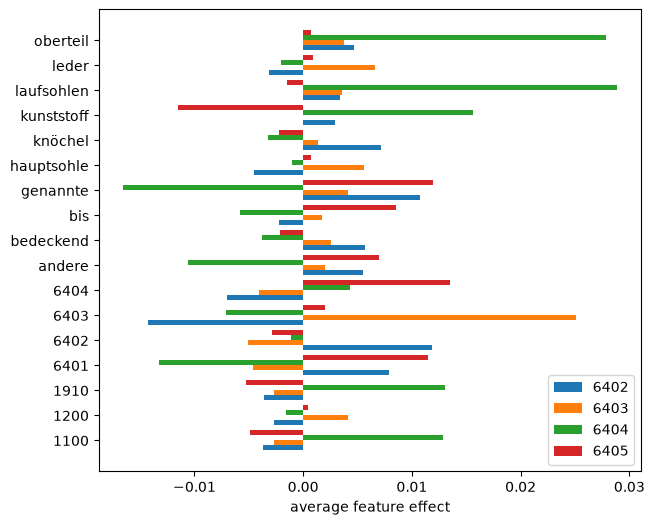

In [25]:
fig, ax = plt.subplots(figsize=(7, 6))
y_locs = np.arange(len(top_idx))
for i, h in enumerate(labels):
    ax.barh(y_locs + (i - 1.5) * 0.2, effects[i, top_idx], height=0.2, label=h)
ax.set(yticks=y_locs, yticklabels=feature_names[top_idx], xlabel="average feature effect")
ax.legend(loc="lower right")
plt.show()

**What do you see?** Which words have a bar for more than one heading?

The most predictive words are mostly positive for one heading and negative for the others: `leder` and `hauptsohle` (main sole) push towards 6403, `oberteil` (upper), `laufsohlen` (outer soles) and `kunststoff` towards 6404. The words are German: the average effect weights by frequency, and most footwear decisions are German. Words shared by several headings (`genannte`, "mentioned", is among the top five of three headings) have bars for more than one heading, which is where confusions start.

## Leakage through the customs' justification

**Target leakage** (Sessions 7 and 9) means that a feature contains information about the label that will not be available when the model is used. Every training decision has a column `classification_justification`, the text in which customs explain their classification. It is written *with* the decision and usually names the result, for example:

> CLASSIFICATION HAS BEEN DETERMINED IN ACCORDANCE WITH THE FOLLOWING: GIR 1 HAS BEEN USED TO CLASSIFY THE PRODUCT BY THE TERMS OF HEADING 4303 ...

It is like grading an exam with the answer key stapled to each paper. A new request has no justification, and a request to the API does not contain it.

Next we measure how often the justification names the heading, and how far a rule gets that simply reads its first four-digit number. `str.extract(pattern, expand=False)` returns the first match of a capture group.

In [26]:
just = train["classification_justification"].fillna("")
print("justification contains the heading:", round(np.mean([h in j for h, j in zip(train["heading"], just)]), 2))
first_number = just.str.extract(r"\b(\d{4})\b", expand=False)
print("first four-digit number = heading: ", round((first_number == train["heading"]).mean(), 2))

justification contains the heading: 0.68


first four-digit number = heading:  0.61


### A model trained with the justification

Now the careless notebook: append the justification to the description, train on the sample and validate on the validation set, where the justification is present as well. Then apply the same model where it will be used: to the validation decisions with their description only, as for a new request.

**Predict.** Which of the two models will be better in use?

In [27]:
with_just = train["description"] + " " + just
valid_just = valid["description"] + " " + valid["classification_justification"].fillna("")
y = train["heading"]
for name, X_tr, X_va in [("description only", train["description"], valid["description"]),
                         ("+ justification", with_just, valid_just)]:
    m = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), svm()).fit(X_tr, y)
    acc_val = accuracy_score(valid["heading"], m.predict(X_va))
    acc_use = accuracy_score(valid["heading"], m.predict(valid["description"]))
    print(f"{name:17s} validation {acc_val:.3f}   in use (description only) {acc_use:.3f}")

description only  validation 0.856   in use (description only) 0.856


+ justification   validation 0.978   in use (description only) 0.797


Validation reports a large jump. In use, where only the description exists, the leaking model is *worse* than the honest one: it learned to rely on a text that is missing, and learned less from the description itself.

No validation scheme detects this, because the justification is present in every validation decision as well. The only protection is to ask, for every column, *"would I have this value at the moment of prediction?"*, and to answer from how the data are produced, not from the scores.

### The same leak in a classic benchmark

*The following example is summarised from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause).* The same kind of leak appears in the classic 20 Newsgroups benchmark: by default the posts contain e-mail headers, signatures and quoted earlier messages. In that example, the word "caltech" is among the most predictive features for the atheism newsgroup, because sender addresses in the metadata identify regular posters. Stripping headers, footers and quotes lowers the score, but the remaining model learns from the content, which is what the task intends.

> **Note.** A large jump in the validation score from one new column is a warning sign, not a success. In the final project, never use `classification_justification`, `keywords`, `cn_code`, `chapter`, `date_of_issue` or `end_date` as inputs; none of them is part of a request. Reading them during error analysis is fine.

**In practice.** Kaufman et al. (2012) use the KDD Cup 2008 breast-cancer data, where patient identifiers predicted the label because of how the data had been assembled, as a textbook case of leakage. In churn data, fields such as "reason for leaving" are filled only for customers who have already left.

## Dimensionality reduction with truncated SVD

The TF-IDF matrix has tens of thousands of sparse columns. **Truncated singular value decomposition** (truncated SVD) approximates it by k dense columns, say 100. Each new column, a **component**, is a weighted combination of words that tend to occur together. Applied to a document-term matrix the method is called **latent semantic analysis** (LSA; Deerwester et al., 1990). In a picture: X ≈ U Σ Vᵀ, where V (words × k) describes each component by its word weights and U Σ (documents × k) gives each document's coordinates on the components.

Truncated SVD is closely related to PCA (Session 11). PCA first subtracts the column means, which would turn every zero into a non-zero number and destroy sparsity; truncated SVD works on the sparse matrix directly.

```mermaid
flowchart LR
    X["TF-IDF matrix<br/>documents x words<br/>sparse"] -->|"TruncatedSVD(k=100)"| Z["LSA features<br/>documents x 100<br/>dense"]
    Z --> P["2-D plot,<br/>clustering (Session 11)"]
    Z --> M["Classifier or trees<br/>(compact features)"]
    X -->|"components_"| W["Word weights<br/>per component"]
```

### What the components capture

Next we fit 100 components on the training TF-IDF matrix of the word model. `explained_variance_ratio_` is the share of variance each component keeps; we print the top and bottom words of components 1–3 (component 0 is close to the average document).

**Predict.** Will the first components separate product groups or languages?

In [28]:
from sklearn.decomposition import TruncatedSVD

T = vec.transform(train["description"])
svd = TruncatedSVD(n_components=100, random_state=0).fit(T)
print("variance kept by 100 components:", round(svd.explained_variance_ratio_.sum(), 2))
for i in [1, 2, 3]:
    c = svd.components_[i]
    print(i, list(names[np.argsort(c)[::-1][:6]]), "vs", list(names[np.argsort(c)[:4]]))

variance kept by 100 components: 0.19
1 ['de', 'en', 'la', 'un', 'et', 'pour'] vs ['mit', 'aus', 'oberteil', 'der']
2 ['oberteil', 'laufsohlen', 'kunststoff', 'spinnstoff', '6404', 'schuhe'] vs ['die', 'sich', 'um', 'es']
3 ['een', 'van', 'met', 'voor', 'het', 'onder'] vs ['la', 'et', 'une', 'un']


The first components separate **languages**, because words of one language co-occur with each other; topics such as footwear appear only in some components.

### LSA features for a classifier

Next we use 300 LSA components as classifier input. `Normalizer()` rescales each row to length 1 again after the projection.

In [29]:
from sklearn.preprocessing import Normalizer

t0 = time.perf_counter()
lsa = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True),
                    TruncatedSVD(n_components=300, random_state=0), Normalizer(), svm())
lsa.fit(train["description"], train["heading"])
report("linear SVM on 300 LSA components", valid["heading"], lsa.predict(valid["description"]), t0)
report("linear SVM on sparse TF-IDF", valid["heading"], pred)

linear SVM on 300 LSA components accuracy 0.682  macro-F1 0.405    58 s
linear SVM on sparse TF-IDF      accuracy 0.856  macro-F1 0.667


The compact representation is much weaker for classification. LSA is mainly a tool for exploration, for plots and for methods that need dense input (k-means, nearest-neighbour search, tree models), and the historical step towards the learned embeddings of Session 14, which do map texts of different languages into one space.

> **Note.** The sign of an SVD component is arbitrary. Interpret components by their top *and* bottom words, and do not expect every component to have a clear meaning.

**In practice.** LSA was developed at Bellcore for information retrieval (Deerwester et al., 1990), so that a search for "car" could also find documents about "automobiles". Landauer and Dumais (1997) reported that LSA trained on an encyclopedia answered the synonym questions of the TOEFL test about as well as applicants from non-English-speaking countries.

### Clustering descriptions with LSA and k-means

*Adapted from [Clustering text documents using k-means](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

#### Scores for a clustering

Clustering is unsupervised (Session 11), but when labels exist we can use them to judge the clusters:

- **homogeneity**: how much each cluster contains members of a single class;
- **completeness**: how much the members of a class end up in the same cluster;
- **V-measure**: the harmonic mean of the two;
- **adjusted Rand index** (ARI): how often pairs of documents are grouped consistently with the classes, adjusted so that random labels score 0 on average;
- the **silhouette coefficient** needs no labels; it compares distances within and between clusters.

To avoid clusters by language, we use only German decisions of the four chapters of the benchmark and ask k-means for four clusters.

In [30]:
from sklearn.cluster import KMeans
from sklearn import metrics

de4 = train[(train["language"] == "de") & train["chapter"].isin(chapters)]
labels_true = de4["chapter"].to_numpy()
vec_de = TfidfVectorizer(max_df=0.5, min_df=5)
X_tfidf = vec_de.fit_transform(de4["description"])
print(f"{X_tfidf.shape[0]:,} documents, {X_tfidf.shape[1]:,} features, "
      f"non-zero share {X_tfidf.nnz / np.prod(X_tfidf.shape):.3f}; chapter sizes",
      de4["chapter"].value_counts().sort_index().to_dict())

9,266 documents, 7,953 features, non-zero share 0.007; chapter sizes {'39': 2048, '64': 1639, '85': 3598, '95': 1981}


#### The random start of k-means

k-means optimises a non-convex objective, so its result depends on the random start. On sparse, high-dimensional text it can place a centre on an isolated document that then stays a cluster of its own. Next we run it five times with one start each (`n_init=1`) and print the cluster sizes; `np.unique(..., return_counts=True)` counts the members per cluster.

In [31]:
for seed in range(5):
    km = KMeans(n_clusters=4, max_iter=100, n_init=1, random_state=seed).fit(X_tfidf)
    print("cluster sizes:", np.unique(km.labels_, return_counts=True)[1])

cluster sizes: [3974  473 1135 3684]
cluster sizes: [1232  473 1133 6428]
cluster sizes: [2593 1608 4003 1062]
cluster sizes: [2015 1608 2001 3642]
cluster sizes: [3696 3963  561 1046]


The cluster sizes change with the seed and can be very unbalanced compared with the chapter sizes. Next we write a function that fits a clustering several times with different seeds and reports the mean and spread of each score.

In [32]:
def fit_and_evaluate(km, X, name, n_runs=3):
    scores = {"homogeneity": [], "completeness": [], "V-measure": [], "ARI": [], "silhouette": []}
    for seed in range(n_runs):
        km.set_params(random_state=seed).fit(X)
        scores["homogeneity"].append(metrics.homogeneity_score(labels_true, km.labels_))
        scores["completeness"].append(metrics.completeness_score(labels_true, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels_true, km.labels_))
        scores["ARI"].append(metrics.adjusted_rand_score(labels_true, km.labels_))
        scores["silhouette"].append(metrics.silhouette_score(X, km.labels_, sample_size=2000, random_state=0))
    print(name, {k: f"{np.mean(v):.3f} ± {np.std(v):.3f}" for k, v in scores.items()})


fit_and_evaluate(KMeans(n_clusters=4, max_iter=100, n_init=5), X_tfidf, "k-means on TF-IDF, n_init=5:\n ")

k-means on TF-IDF, n_init=5:
  {'homogeneity': '0.726 ± 0.001', 'completeness': '0.851 ± 0.002', 'V-measure': '0.784 ± 0.001', 'ARI': '0.728 ± 0.001', 'silhouette': '0.041 ± 0.000'}


#### k-means on LSA components

All scores have a maximum of 1. Next we reduce the TF-IDF matrix to 100 LSA components first, normalise the rows again, and cluster with a single start.

In [33]:
lsa_de = make_pipeline(TruncatedSVD(n_components=100, random_state=0), Normalizer(copy=False))
X_lsa = lsa_de.fit_transform(X_tfidf)
print(f"variance kept: {lsa_de[0].explained_variance_ratio_.sum():.1%}")
kmeans = KMeans(n_clusters=4, max_iter=100, n_init=1)
fit_and_evaluate(kmeans, X_lsa, "k-means on LSA, n_init=1:\n ")

variance kept: 38.6%
k-means on LSA, n_init=1:
  {'homogeneity': '0.774 ± 0.037', 'completeness': '0.830 ± 0.031', 'V-measure': '0.801 ± 0.030', 'ARI': '0.743 ± 0.092', 'silhouette': '0.127 ± 0.008'}


Compare the two lines: with LSA, a single start reaches higher homogeneity, V-measure and ARI on average than five starts on the raw TF-IDF matrix, with a larger spread between seeds, and it is much cheaper. The original example finds the same on news posts and explains it by the curse of dimensionality, which hurts k-means on raw text. The silhouette is low in both cases; strictly, it should not be compared across spaces of different dimension.

#### Top terms per cluster

Because the SVD can be inverted approximately, we can map the cluster centres back to the word space with `inverse_transform` and read the top terms of each cluster.

In [34]:
centroids = lsa_de[0].inverse_transform(kmeans.cluster_centers_)
terms = vec_de.get_feature_names_out()
for i, row in enumerate(centroids.argsort()[:, ::-1][:, :8]):
    members = pd.Series(labels_true[kmeans.labels_ == i]).value_counts().head(2).to_dict()
    print(f"cluster {i}: {' '.join(terms[row])}  | chapters {members}")

cluster 0: zum zur elektrischen spannung oder mm eine abbildung  | chapters {'85': 3587, '39': 59}
cluster 1: oberteil kunststoff laufsohlen genannte spinnstoff 6404 spinnstoffen 6403  | chapters {'64': 1614}
cluster 2: spielzeug cm 9503 ein ca darstellend unterhaltung spielerischen  | chapters {'95': 1330, '39': 15}
cluster 3: sich es um handelt 3926 kunststoffen zu cm  | chapters {'39': 1974, '95': 633}


Read the clusters against the chapters: electrical goods form a clean cluster of their own, and so does footwear, with words of both footwear headings among its top terms (`oberteil`, `laufsohlen`, `spinnstoff`). Toys get a cluster of their own as well (`spielzeug`, `unterhaltung`), but only for about two thirds of them: 633 toy decisions sit in the plastics cluster, held together by the general phrasing "es handelt sich um" (it is a ...) and measurements in cm. Clusters follow whatever co-occurs most, which is not always what we care about.

> 📖 **Read more:** [extras/05-sklearn-document-clustering-lsa.ipynb](extras/05-sklearn-document-clustering-lsa.ipynb) (scikit-learn gallery): the original example on news posts, with `MiniBatchKMeans`, a `HashingVectorizer` + `TfidfTransformer` + LSA pipeline, and a summary plot of all clustering scores and times.

## The limits of word counts

### Four blind spots

Bag-of-words, TF-IDF and n-grams share four blind spots:

1. **Other languages and synonyms.** "Spielzeugauto aus Kunststoff", "Voiture jouet en matière plastique" and "Toy car of plastics" describe the same good but share no word. The model must learn each language from labelled examples; for Bulgarian or Slovak there are few.
2. **Word order beyond n words.** "Shoes with a textile upper and a leather sole": bigrams help only if material and part stand next to each other.
3. **Ambiguity.** "Zubehör" (accessories) or "set" mean different things for different goods; one column has many meanings.
4. **Unknown words and short texts.** A word that is not in the training vocabulary gets no column, and a short description gives the model little to go on.

Each limit has a classic patch: n-grams (order), stemming and LSA (synonyms within one language), character n-grams (compounds, unknown words). None solves the problem in general, because all of them still represent a word by its identity, not by its meaning. **Language models** learn from large amounts of unlabelled text, in many languages, that "jouet", "Spielzeug" and "toy" occur in similar contexts, and represent texts as dense vectors in which such descriptions are close (Session 14).

### Synonyms across languages

**Predict.** What is the cosine similarity of the TF-IDF vectors of the three toy-car descriptions? `cosine_similarity` compares every row with every other row.

In [35]:
from sklearn.metrics.pairwise import cosine_similarity

same_good = ["Spielzeugauto aus Kunststoff", "Voiture jouet en matière plastique", "Toy car of plastics"]
print(cosine_similarity(TfidfVectorizer().fit_transform(same_good)).round(2))

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


### An unknown compound

Next a short German description of a replacement head for electric toothbrushes. We check whether its words are in the vocabulary of the word model (`in vec.vocabulary_`) and what the model predicts.

In [36]:
short = "Aufsteckbürste für elektrische Zahnbürsten"
print({w: w in vec.vocabulary_ for w in ["aufsteckbürste", "elektrische", "zahnbürsten"]})
guess = model.predict([short])[0]
print(guess, heading_text[guess][:50], "| true heading would be 9603 (brushes)")

{'aufsteckbürste': False, 'elektrische': True, 'zahnbürsten': True}


6815 Articles of stone or of other mineral substances ( | true heading would be 9603 (brushes)


### From word counts to language models

```mermaid
timeline
    title From word counts to language models
    1972 : idf weighting (Spärck Jones)
    1990 : LSA, truncated SVD of the term matrix
    2003 : Topic models (LDA)
    2013 : word2vec word embeddings
    2017 : Transformer and attention
    2018 : BERT and GPT, pre-trained language models
    2019 : Multilingual sentence embeddings
```

> **Note.** Keep the TF-IDF classifier as the baseline for every later text model in the project. A language model is worth its extra cost only if it beats this baseline on the same validation set by a margin that matters (Session 14).

**In practice.** Many production search systems still use BM25 or TF-IDF for a first, cheap retrieval step and a language model only for re-ranking the top results, combining the speed of counts with the semantics of embeddings (Session 15).

## Worked example · Checkpoint 1: your validation design and score

At the end of this session every team posts on the class board how it validates and what it measures: **checkpoint 1** of the final project. The checkpoint is not graded. It lets every team see how the others validate, and it is the first point of a line that ends with the independent score in Session 18. A post has four parts: the split design, the model, the score with its uncertainty, and what the score does not cover. We prepare it for the word model of this block.

### Step 1 · The score with a bootstrap interval

**Why this step?** Why post an interval and not only the score?

14,635 validation decisions give a precise accuracy, but not an exact one. A **bootstrap** (Session 7) resamples the validation decisions with replacement, recomputes accuracy and macro-F1 each time, and takes the 2.5 % and 97.5 % percentiles as a 95 % interval. `rng.integers(0, n, n)` draws n positions with replacement; macro-F1 is slow to compute, so we use 200 resamples.

In [37]:
rng = np.random.default_rng(0)
y_true = valid["heading"].to_numpy()
boot = []
for _ in range(200):
    i = rng.integers(0, len(y_true), len(y_true))
    boot.append((accuracy_score(y_true[i], pred[i]), f1_score(y_true[i], pred[i], average="macro", zero_division=0)))
low, high = np.percentile(boot, [2.5, 97.5], axis=0)
acc, mf1 = accuracy_score(y_true, pred), f1_score(y_true, pred, average="macro")
print(f"accuracy {acc:.3f}, 95 % interval [{low[0]:.3f}, {high[0]:.3f}]")
print(f"macro-F1 {mf1:.3f}, 95 % interval [{low[1]:.3f}, {high[1]:.3f}]")

accuracy 0.856, 95 % interval [0.851, 0.861]
macro-F1 0.667, 95 % interval [0.658, 0.690]


The accuracy interval is narrow, about half a point on either side. The macro-F1 interval is wider and not centred on the estimate (0.667 lies near its lower end): a resample leaves out about a third of the headings with a single validation decision, many of them with F1 = 0, which changes what is averaged. Treat it as a rough guide. Note also what neither interval covers: the choice of settings on these validation decisions, the luck of this particular split (see the reference values in the section on linear models), and change over time (the split by date).

### Step 2 · The post for the class board

Next we write the post as Markdown text filled from the variables above, so that the numbers in the post are the numbers of the notebook. In an f-string, `{value:.3f}` inserts a number with three decimals and `{n:,}` with a thousands separator.

In [38]:
post = f"""**Team X · checkpoint 1**
- Split: one fold of a stratified 7-fold split by heading and language (random_state=0), {len(train_full):,} training and {len(valid):,} validation decisions
- Model: word TF-IDF (min_df=2, sublinear tf) + linear SVM (SGDClassifier, hinge, alpha=1e-5), trained on a sample of {len(train):,} training decisions
- Inputs: the description only
- Validation score: accuracy {acc:.3f} [{low[0]:.3f}, {high[0]:.3f}], macro-F1 {mf1:.3f} [{low[1]:.3f}, {high[1]:.3f}] (95 % bootstrap intervals)
- Split by date (newest {len(date_valid):,} decisions): accuracy {split_scores['by date'][0]:.3f}, macro-F1 {split_scores['by date'][1]:.3f}
- Not covered: settings were chosen on the same validation decisions, so the score is slightly optimistic"""
print(post)

**Team X · checkpoint 1**
- Split: one fold of a stratified 7-fold split by heading and language (random_state=0), 87,805 training and 14,635 validation decisions
- Model: word TF-IDF (min_df=2, sublinear tf) + linear SVM (SGDClassifier, hinge, alpha=1e-5), trained on a sample of 50,000 training decisions
- Inputs: the description only
- Validation score: accuracy 0.856 [0.851, 0.861], macro-F1 0.667 [0.658, 0.690] (95 % bootstrap intervals)
- Split by date (newest 14,635 decisions): accuracy 0.765, macro-F1 0.520
- Not covered: settings were chosen on the same validation decisions, so the score is slightly optimistic


### Step 3 · The API check of Session 16

There is nothing to upload: the checkpoint is the design and the score, not a file of predictions. The same validation decisions will later check your service. From Session 16 on, your model answers behind a REST API (`POST /predict` with a description, answering the heading; the interface is fixed in the [final project](../../17-18-final-presentations/final-project.md)), and `case-study/evaluate_api.py` sends every description of a file to it and prints accuracy and macro-F1, the same way the lecturer evaluates the final service:

```bash
uv run python case-study/evaluate_api.py --url http://localhost:8000 --data my_validation.parquet
```

Run on your validation decisions, it must reproduce the score you posted. A large gap points to a bug between the notebook and the service (another preprocessing, another model file), not to bad luck.

### Step 4 · Refitting for the service

**Why this step?** Why may the validation labels become training data once the settings are fixed, and what can the team then no longer measure?

Once the design and the settings are fixed, the validation labels are training data like any other, so the deployed model is usually refitted on all 102,440 decisions. Its score can then no longer be measured on decisions it has seen: the team reports the validation score measured before the refit and says so (final project, questions and answers). The case-study README shows what more training data gives: 0.877 accuracy on the full training part of 87,805 decisions, against 0.856 on 50,000. Fitting on the full training part takes much longer than on the sample and needs several GB of memory; set `RUN_FULL = True` in the next cell to measure it on our validation decisions.

In [39]:
RUN_FULL = False
if RUN_FULL:
    big = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True, max_features=400_000),
                        SGDClassifier(loss="hinge", alpha=2e-6, max_iter=20, tol=None, random_state=0, n_jobs=-1))
    big.fit(train_full["description"], train_full["heading"])
    report("word model, full training part", valid["heading"], big.predict(valid["description"]))
else:
    print("Full training part skipped (RUN_FULL = False).")

Full training part skipped (RUN_FULL = False).


Record the post in the team log as well. Checkpoint 2 in Session 14 asks whether embeddings or a language model improve this score, measured on the same validation decisions.

## Check your understanding

Vote alone first, then discuss with your neighbour and vote again.

**1.** A model predicts 9503 for 40 decisions, 30 of them correctly; the validation set has 120 decisions of 9503. What are precision and recall of 9503?

- A. precision 0.25, recall 0.75
- B. precision 0.75, recall 0.25
- C. precision 0.75, recall 0.75
- D. precision 0.75, recall 0.33

**2.** Always predicting 3926 gives an accuracy of 0.042 on the validation part. What macro-F1 do you expect?

- A. about 0.04, the same as the accuracy
- B. about 0.08, the F1 of 3926
- C. close to 0, because every other heading has F1 = 0 and macro-F1 averages over all headings
- D. none: macro-F1 cannot be computed when most headings are never predicted

**3.** The split by date reports 0.765 accuracy and the random stratified split 0.856, with 50,000 training decisions each. Which explanation fits the outputs of the split section?

- A. The split by date has more exact repeats of training texts.
- B. Many of the newest decisions have a heading that never occurs in training.
- C. The split by date validates on fewer decisions.
- D. Products, wording and traders change, and the newest decisions have no training decisions from the same weeks.

**4.** A teammate fits the `TfidfVectorizer` on all 102,440 decisions and only then splits them into training and validation decisions. What happens to the validation accuracy?

- A. Nothing: the vectoriser never sees a heading, so nothing can leak.
- B. It becomes slightly optimistic: vocabulary and idf were learned partly from the validation texts.
- C. It becomes pessimistic: validation words dilute the vocabulary.
- D. The split fails, because the validation rows are already transformed.

**5.** A teammate adds `keywords` to the description and reports 0.93 validation accuracy. What will the independent evaluation through the team's API show?

- A. A lower score, probably below the description-only model, because requests contain no keywords.
- B. About 0.93, because the validation design was sound.
- C. More than 0.93, because the service is refitted on all decisions.
- D. About the same as without keywords, because the keywords are in English and most descriptions are not.

## Exercises

Work in pairs. The lecturer picks which exercises to set; there are more than fit into the time in class. Solve *Paper*, *Parsons* and *Find the bug* tasks without a laptop first. The *Code* tasks use `model`, `pred`, `val`, `train`, `valid`, `taric` and `heading_text` from the cells above; the last exercises lead into the team project.

### 2.1 · Naive Bayes by hand

*Paper*

> Training data: negative "just plain boring", "entirely predictable and lacks energy", "no surprises and very few laughs"; positive "very powerful", "the most fun film of the summer". With add-one smoothing (vocabulary of 20 words), classify "predictable with no fun".
>
> *Stretch:* what happens without smoothing?

*Source:* [Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft), Appendix B: Naive Bayes, worked example](https://web.stanford.edu/~jurafsky/slp3/B.pdf)

*Your answer:*

### 2.2 · Humans against the baseline

*Class*

> Classify ten descriptions into HS chapters by hand. How does the class compare with TF-IDF?
>
> The cell below shows ten English descriptions from the validation set and the list of chapters. Write down one two-digit chapter per description (the class may vote). Then compare your answers with the true chapters and with the chapters of the model's predictions (`val["pred"].str[:2]`).

*Source:* original exercise for this course; background: [Karpathy (2014), "What I learned from competing against a ConvNet on ImageNet"](http://karpathy.github.io/2014/09/02/what-i-learned-from-competing-against-a-convnet-on-imagenet/)

In [40]:
# Setup: ten English descriptions and the list of chapters.
ten = val[val["language"] == "en"].sample(10, random_state=7)
for i, text in enumerate(ten["description"], start=1):
    print(i, " ".join(text.split())[:200])
chapters = sorted({h[:2] for h in heading_text.index})
chapter_names = pd.Series({c: taric[f"{c}00000000 80"] for c in chapters}).str[:60]
print(chapter_names.to_string()[:1500], "...")

1 Detection Sensor. It is uses microwave and infrared sensors to activate (open/close) automatic doors. The sensor detects movement in the reflection levels of the transmitted signal, this causes a mech
2 A gas fuelled space heater It’s function is to provide heat by burning gas. Typically installed in caravans or motorhomes Made from various materials including glass filled nylon for the outer casing 
3 The product is a ready to drink high protein Chocolate shake. Each bottle contains 48 grams of protein to boost muscle mass and 48 grams of carbohydrates to support recovery. These products contain le
4 Bag Charm is designed to be attached to and decorate a bag. It contains various decorative parts. Metal (zinc) is the predominant material by weight and cost.
5 THIS IS A PORTABLE ADP MACHINE WHICH ALLOWS THE USER TO EXECUTE COMPUTER PROGRAMS AND SOFTWARE APPLICATIONS, BROWSE THE INTERNET, COMPOSE EMAILS AND PERFORM AN ARRAY OF OTHER TASKS SIMILAR TO THOSE AV
6 A plastic cover suitable 

*Your answer:*

### 2.3 · The fallback heading of chapter 39

*Code*

> The error-analysis section read the confusion matrix of the footwear headings. Do the same for the plastic articles 3923 (containers, closures), 3924 (tableware, household articles), 3925 (builders' ware) and 3926 (other articles of plastics). Which heading acts as the model's fallback? Compute precision and recall of 3926 from the matrix and check them with `classification_report`.

*Source:* original exercise for this course.

### 2.4 · Ten errors in another language

*Pairs*

> Draw ten misclassified **French** (or Polish) decisions from the validation set with `random_state=2`. Read each one with its English keywords and the English texts of the true and the predicted heading, and give each one category from the list in the error-analysis section (borderline, material versus function, rare language, technical, set, new heading, unclear). Does the distribution differ from the 20 errors read there?

*Source:* original exercise for this course; background: Ng, *Machine Learning Yearning* (2018), chapters on error analysis.

### 2.5 · What does the model rely on for two other headings?

*Code*

> List the twelve n-grams with the largest coefficients for heading 2106 (food preparations not elsewhere specified) and 9405 (luminaires and lighting fittings). Which languages do they come from? Would you trust the model for a Greek description of a lamp?

*Source:* original exercise for this course.

### 2.6 · Humans write the classifier

*Paper*

> Write five words that signal a positive film review and five that signal a negative one. A review is classified by counting hits; ties are guessed. Predict your accuracy. Then compare in class.

*Source:* [Pang, Lee & Vaithyanathan (2002), "Thumbs up? Sentiment classification using machine learning techniques", EMNLP](https://aclanthology.org/W02-1011/)

*Your answer:*

### 2.7 · Improve the classifier

*Pairs*

> Pick one error category from the error-analysis section (or from exercise 2.4) and make **one** change to the word model that targets it, for example `min_df`, `max_df`, `ngram_range`, `sublinear_tf`, `alpha`, `class_weight="balanced"`, or a cleaning step before the vectoriser. Train on the sample and report on the validation set: accuracy and macro-F1, overall and for the error category you targeted. Write one line for your team log: change, the three numbers, and whether you keep it.

*Source:* original exercise for this course.

### 2.8 · Character n-grams for the rare languages

*Code*

> *Stretch:* Fit a character model (`TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True, max_features=300_000)` with the same linear SVM) and compare its validation accuracy with the word model **per language**. Do character n-grams help the languages with fewer than 500 training decisions more than German and French? How many validation decisions does each language have, and how far would you trust the per-language numbers?

*Source:* original exercise for this course; background: [Cavnar & Trenkle (1994), "N-gram-based text categorization"](https://www.let.rug.nl/~vannoord/TextCat/textcat.pdf)

### 2.9 · Which split answers the customs office?

*Paper*

> The random split of this block draws its validation decisions from the same weeks as the training data. Give two reasons why a split by start date can report a lower score. A customs office will deploy the model next year: which of the two numbers answers its question, and which one predicts the independent score of the final project?

*Source:* original exercise for this course; background: [Kapoor and Narayanan (2023), "Leakage and the reproducibility crisis in machine-learning-based science"](https://doi.org/10.1016/j.patter.2023.100804)

*Your answer:*

### 2.10 · Put the top-k cell in order

*Parsons*

> The lines below compute the top-k accuracy of the word model, shuffled. Put them in an order that runs and prints the four lines of the section on top-k accuracy. What does one row of `order` hold?
>
> ```python
> classes = model.classes_
>     print(f"top-{k:<2d} accuracy {(classes[order[:, :k]] == y_val[:, None]).any(axis=1).mean():.3f}")
> order = np.argsort(-scores, axis=1)
> for k in [1, 3, 5, 10]:
> scores = model.decision_function(valid["description"])
> y_val = valid["heading"].to_numpy()
> ```

*Source:* original exercise for this course, on the section on top-k accuracy.

*Your answer:*

### 2.11 · Find the bug: three headings too many

*Find the bug*

> A teammate summarises the per-heading report. The code runs, but all three printed numbers are off. Find the bug and fix it.
>
> ```python
> per_heading = pd.DataFrame(classification_report(valid["heading"], pred, output_dict=True,
>                                                  zero_division=0)).T
> print(len(per_heading), "headings in the validation set;",
>       int((per_heading["support"] < 5).sum()), "with fewer than 5 decisions")
> print("mean F1 over the headings:", round(per_heading["f1-score"].mean(), 3))
> ```

*Source:* original exercise for this course; background: [scikit-learn API: `classification_report`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)

*Your answer:*

## Debrief

- **Chapter 39 (2.3).** Look for the wrong precision of 3926 computed from the 4 × 4 matrix alone: it ignores predictions of 3926 for decisions of other chapters. Ask which denominator each pair used.
- **Error categories (2.4).** Compare the *counts* per category across pairs rather than arguing about the label of a single decision; disagreement on borderline cases is itself a finding.
- **Improvements (2.7).** Collect the changes and their three numbers on the board. Which changes help the targeted error category? Which gains are smaller than the differences you would get from another random seed?
- **Find the bug (2.11).** Ask what the last three rows of the report are, and which printed numbers they changed.
- **Humans against models (2.2, 2.6).** Ten items are far too few to compare humans and a model; say so before anyone declares a winner.
- **Bridge to Session 14.** The errors that remain are rare languages, synonyms and rules the model cannot see. Session 14 replaces word counts with embeddings and asks a language model, and both must beat today's checkpoint-1 score on the same validation decisions.

**Team project until the next teaching day.** A TF-IDF classifier on the team's own validation design, error analysis, and checkpoint 1 on the class board: split design, model, accuracy and macro-F1 with intervals, and what the score does not cover.

## Further reading

- Jurafsky, D. and Martin, J. H. *Speech and Language Processing*, 3rd ed. draft, chapters on naive Bayes and text classification, and logistic regression. https://web.stanford.edu/~jurafsky/slp3/
- Manning, C. D., Raghavan, P. and Schütze, H. (2008). *Introduction to Information Retrieval*, chapters 13–15 (text classification, naive Bayes, vector space classification, SVMs) and 18 (LSA). https://nlp.stanford.edu/IR-book/
- scikit-learn developers. *Classification of text documents using sparse features* and *Clustering text documents using k-means* (examples, BSD-3-Clause). https://scikit-learn.org/stable/auto_examples/text/
- Joulin, A., Grave, E., Bojanowski, P. and Mikolov, T. (2017). Bag of tricks for efficient text classification. *Proceedings of EACL 2017*, 427–431. https://aclanthology.org/E17-2068/
- Deerwester, S. et al. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science*, 41(6), 391–407.
- Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012). Leakage in data mining: formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 15.
- Kapoor, S. and Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, 4(9), 100804. https://doi.org/10.1016/j.patter.2023.100804
- Ng, A. (2018). *Machine Learning Yearning*, chapters on error analysis. https://info.deeplearning.ai/machine-learning-yearning-book
- European Commission. *European Binding Tariff Information (EBTI)*. https://taxation-customs.ec.europa.eu/online-services/online-services-and-databases-customs/european-binding-tariff-information-ebti_en
- World Customs Organization. *What is the Harmonized System (HS)?* https://www.wcoomd.org/en/topics/nomenclature/overview/what-is-the-harmonized-system.aspx
- Extras of this block: [04 text classification with sparse features](extras/04-sklearn-text-classification-sparse-features.ipynb), [05 document clustering with LSA](extras/05-sklearn-document-clustering-lsa.ipynb); provenance in [extras/README.md](extras/README.md).

*Course material, CC BY 4.0; sections marked "Adapted from" curate BSD-3-Clause code and text of the scikit-learn developers. Case-study data: European Commission, EBTI database (reuse under Commission Decision 2011/833/EU); TARIC nomenclature of 1 October 2026 (European Commission, same reuse conditions).*